# TFT - market coupling and foreign markets

The three models are nested. d1 uses Polish inputs only. d2 adds the market-coupling block: AC exchange, cross-border flows into Poland, and the Polish system series `np_PL`, `gen_PL`, `vload_PL`, `min_PL` and `max_PL`. d3 adds foreign markets: neighbour loads and net positions, price spreads, and the DE–CZ and CZ–SK flows. Each bar is the mean variable-selection share over the five test seeds. Inside one model the shares sum to 100%.

The left panel is the encoder, the history the model can see. The right panel is the decoder, what is known for the forecast day: the calendar, the day-ahead forecasts and the scheduled exchange. A smaller slice for the same name in a later model is its share of a larger input set.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

from src.utils.tft.feature_importance import mean_shares, plot_blocks, plot_step

shares = mean_shares()


## Block shares

On the encoder the coupling block takes 35% of d2. In d3 it is 21% and foreign markets take 30%, while Poland stays the largest block at 49%.

On the decoder coupling is the largest part of d2, at 53%, ahead of the Polish features at 47%. In d3 the three blocks are closer: Poland 40%, market coupling 33% and foreign markets 27%.

Poland remains the largest encoder block after both extensions. On the decoder the coupling block passes it already in d2, and in d3 the three blocks lie within 13 points of each other.

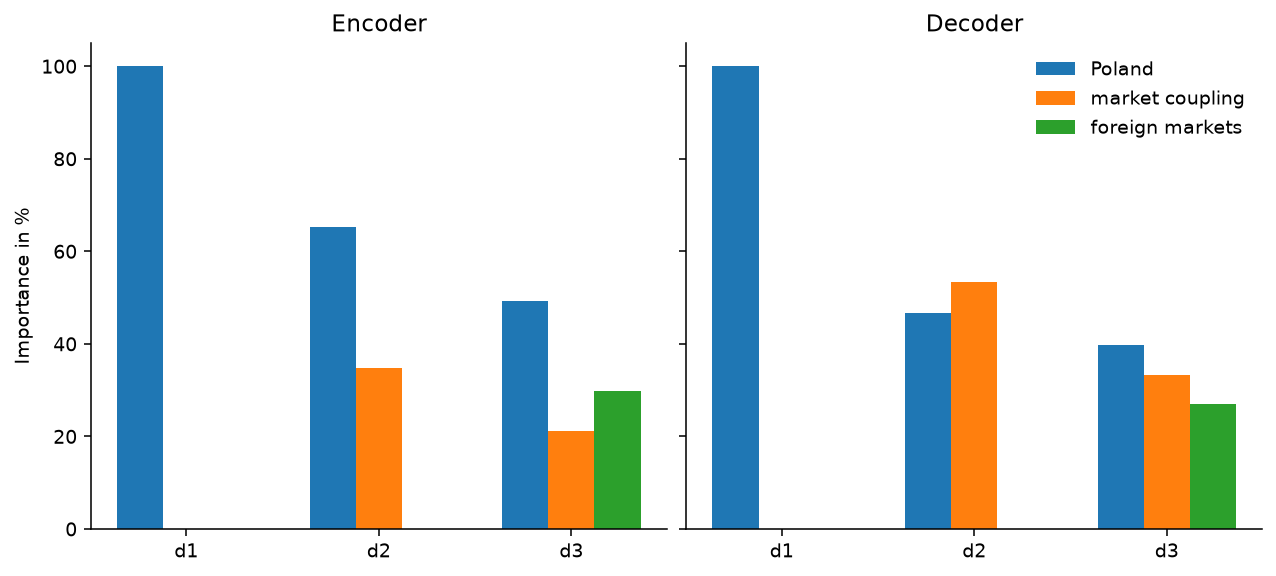

In [2]:
plot_blocks(shares)


## d1

This is the baseline, so every bar is a Polish input. Past `PL_price` leads the encoder at 13%, ahead of EUA and the Polish generation and wind forecasts. On the decoder the holiday flag leads at 15%, followed by the day-ahead price lag at 13% and the load-forecast change at 11%.

The model has 20 encoder series and 11 decoder series. The three price lags on the decoder add up to 33%, so recent Polish prices outweigh the holiday flag once they are counted together.

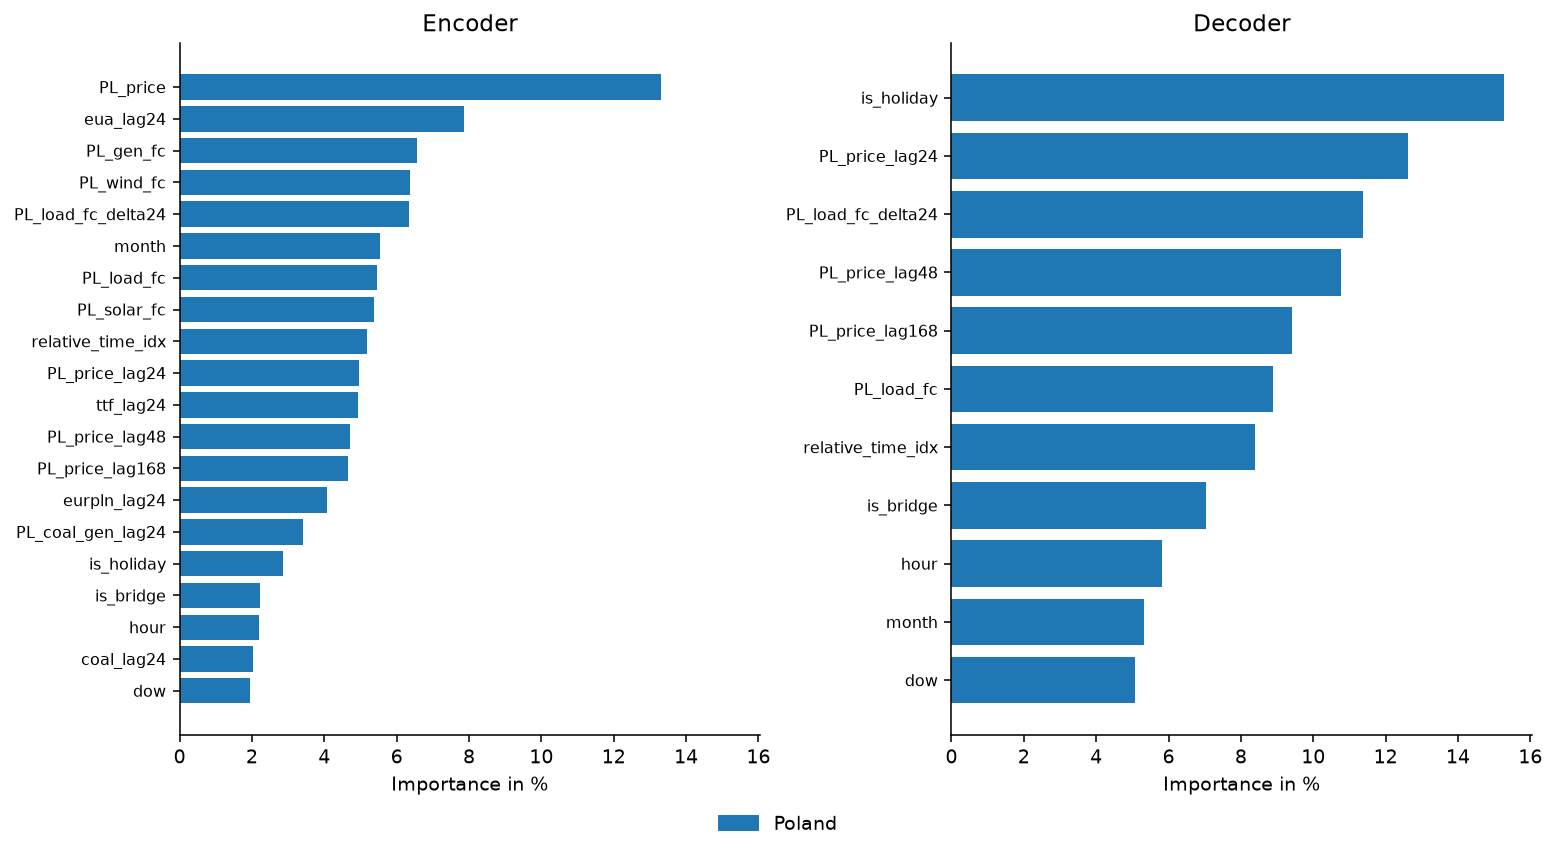

In [3]:
plot_step(shares, "d1")


## d2

Orange bars are the coupling block. Past price is still first on the encoder (7%), and the Ukraine flow is the largest new input (6%). The decoder ranking changes: AC import (8%) and AC export (7%) lead, just ahead of `PL_price_lag24`.

The coupling block is 11 series on each side. On the encoder only the Ukraine flow stands out among them. On the decoder the two AC schedules, the Slovakia flow and `np_PL` each clear 5%.

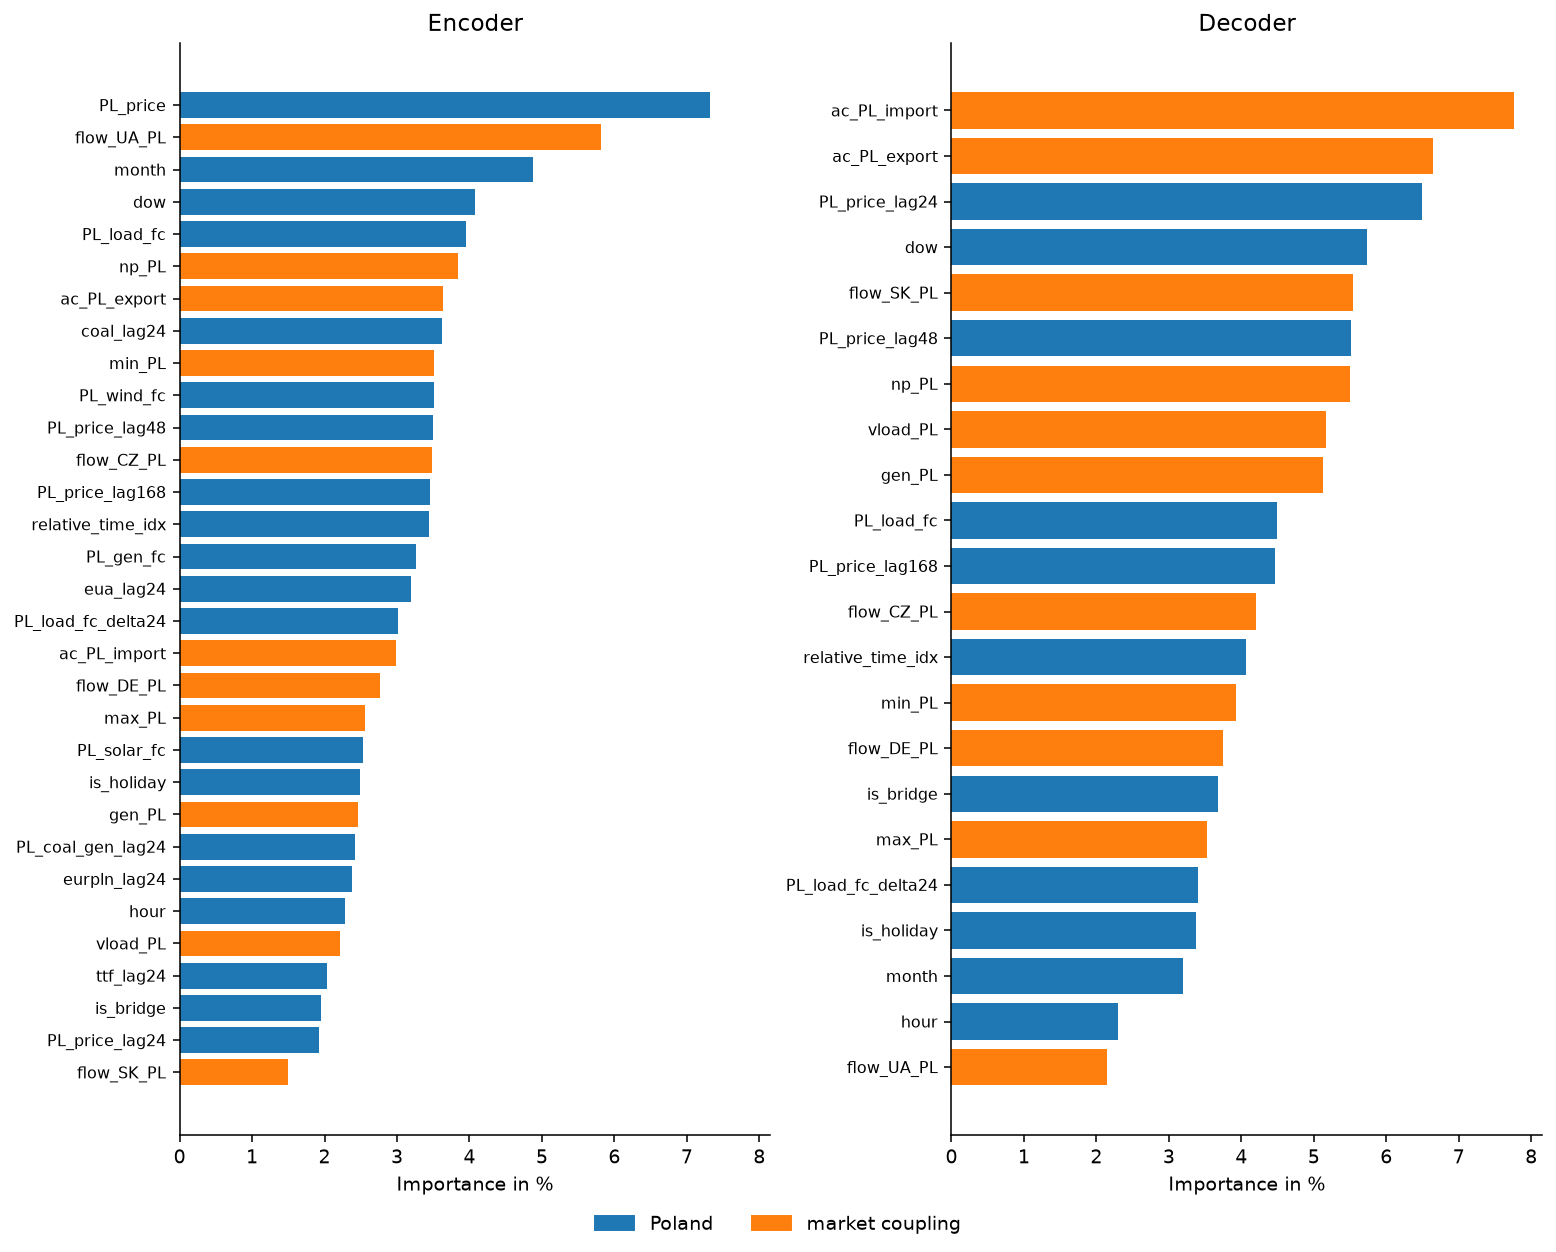

In [4]:
plot_step(shares, "d2")


## d3

Green bars are foreign markets. On the encoder the past price (10%) and the two fuel prices lead, and the largest foreign names, the price spreads, stay near 2–3%. On the decoder `PL_price_lag24` is first (9.4%) and `ac_PL_export` is second (8.6%). The largest single foreign input is `np_50Hz` at 3.3%, so the foreign share is spread across many series.

Sixteen foreign series enter the encoder and the largest of them, `np_SK`, is 2.6%. On the decoder the two AC schedules together take 14%, against 3.3% for the largest foreign name.

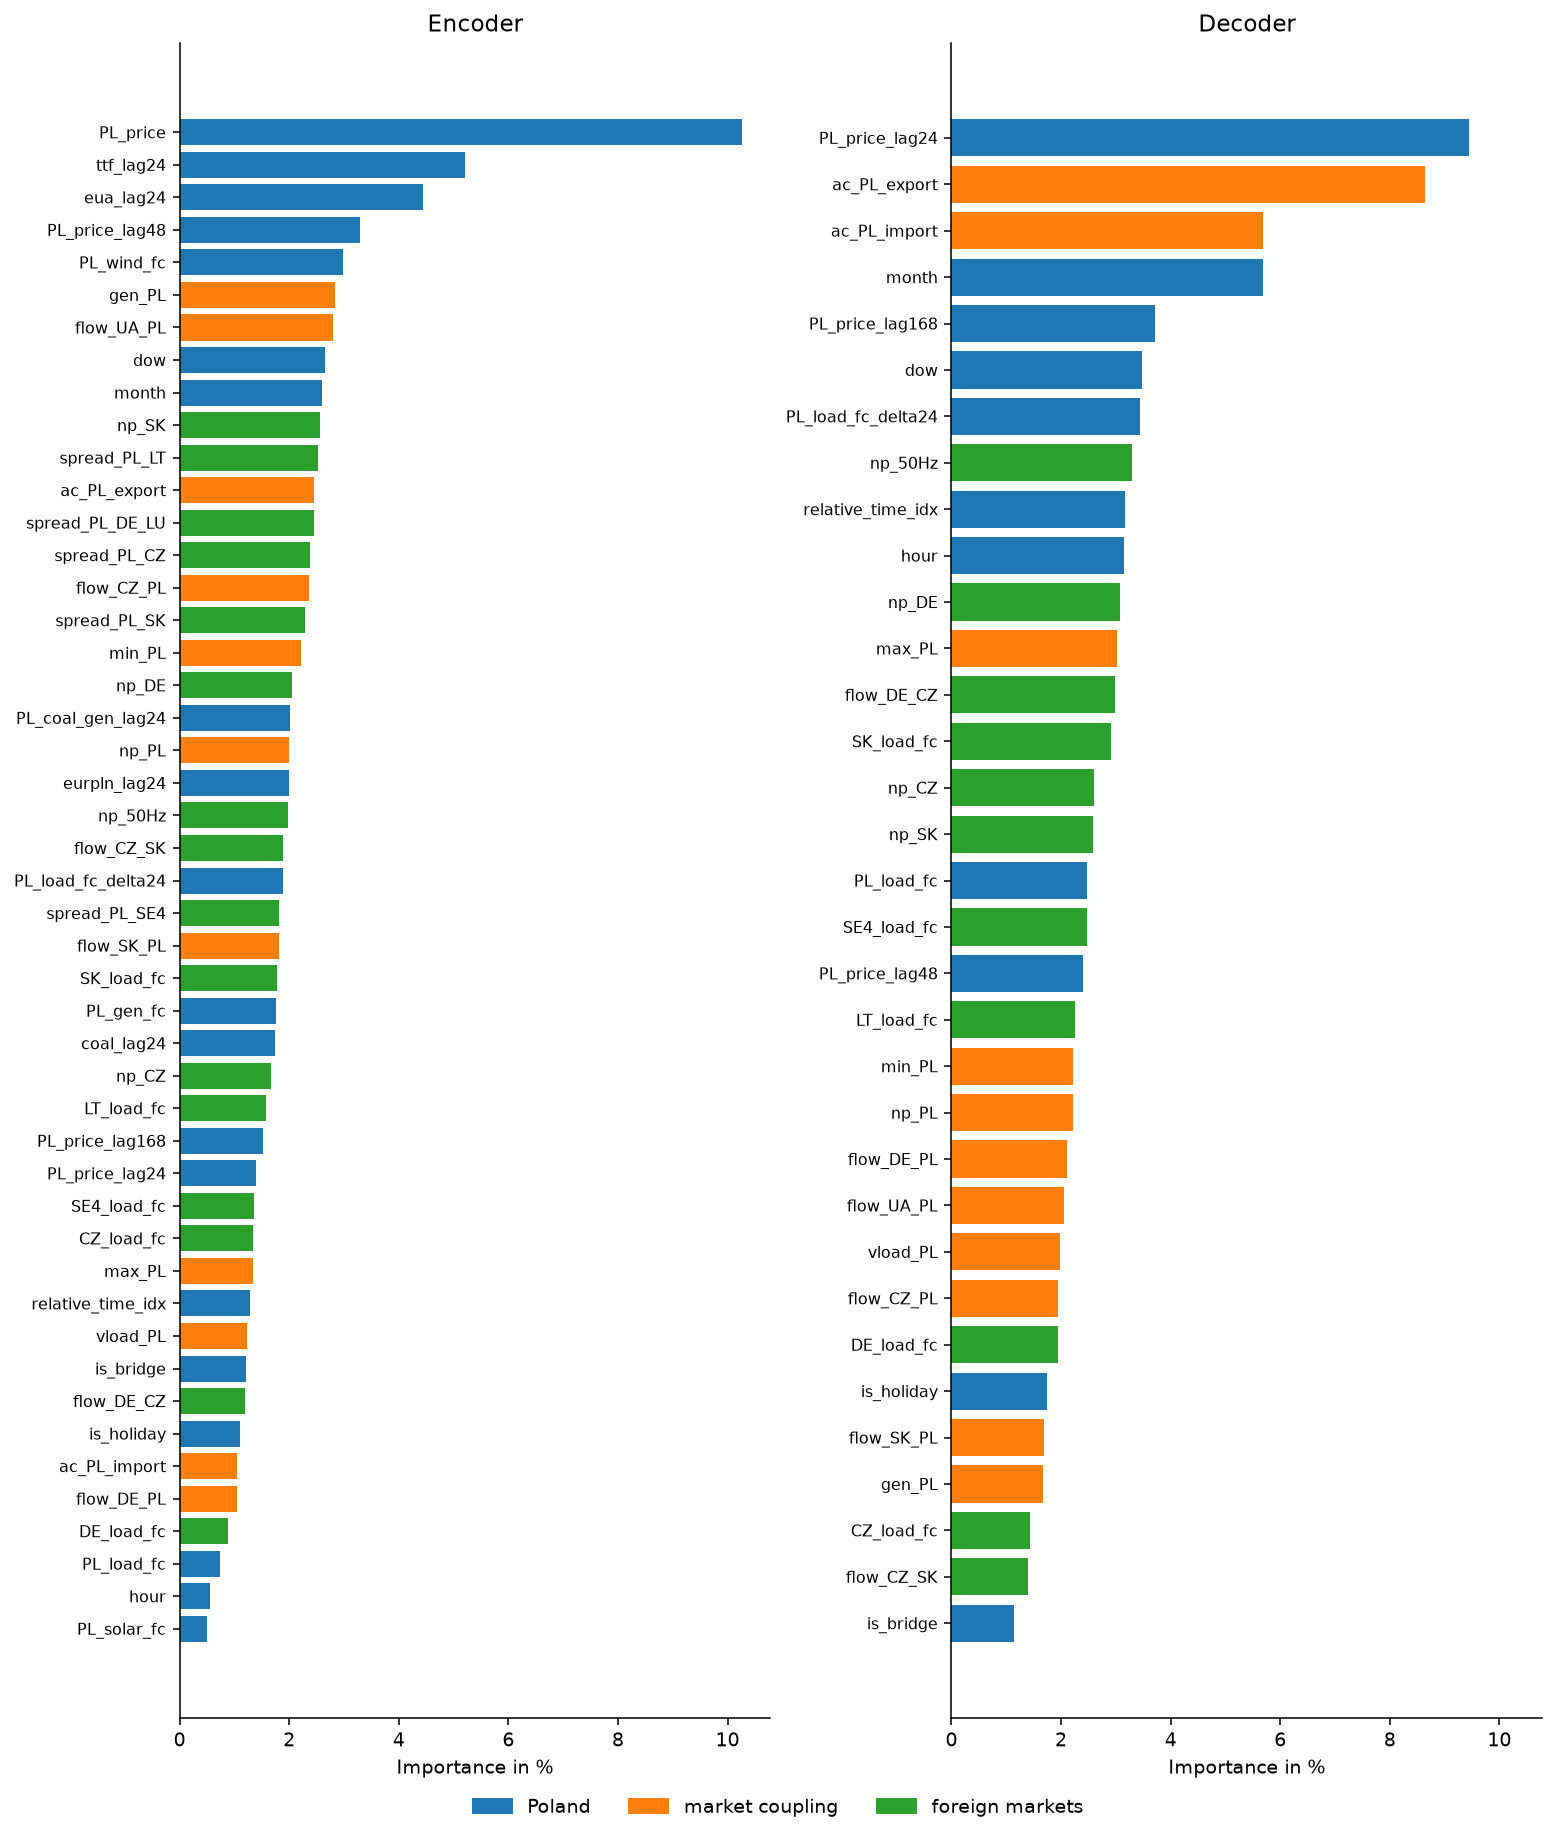

In [5]:
plot_step(shares, "d3")


## Conclusions

Market coupling carries a large part of the forecast. On the decoder it is the biggest block in d2 (53%) and still a third of d3, led by `ac_PL_export` and `ac_PL_import`. Foreign markets add 30% of the encoder and 27% of the decoder, as many small weights rather than one dominant series. The largest decoder input in the full model remains the Polish price lag, with scheduled export immediately behind it.

The price lags that led the d1 decoder stay in the full model, with scheduled export directly behind the first of them. The foreign 27–30% is a sum of series that individually stay at or below 3.3%.